# Demo detekcji punktów na wykresach

Notebook pokazuje krok po kroku, jak metoda bazowa i metoda `line_aware` przekształcają obraz oraz jakie punkty ostatecznie wykrywają.

**Zakres demonstracji:**

- jeden wykres punktowy (`scatter_plot`),
- jeden wykres punktowo-liniowy (`line_scatter_plot`),
- dwie metody detekcji: `baseline` i `line_aware`,
- porównanie obrazu wejściowego, masek pośrednich i wykrytych punktów.

## 1. Przygotowanie środowiska

W tej sekcji importujemy biblioteki i wskazujemy katalog z wygenerowanymi obrazami oraz ich metadanymi.

In [1]:
from pathlib import Path
import json
import math
import sys

import cv2
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.scatter_detection.constants import X_MIN, X_MAX, Y_MIN, Y_MAX
from src.scatter_detection.utils.detection import (
    create_image_mask,
    detect_points,
    detect_points_line_aware,
    isolate_plot_area,
    remove_thin_structures,
)

DATA_DIR = PROJECT_ROOT / "src" / "scatter_detection" / "data" / "generated_data"

## 2. Przygotowanie danych demonstracyjnych

### 2.1. Konfiguracja geometrii wykresu

Dla każdego obrazu odtwarzamy konfigurację geometryczną używaną przez pipeline:

- `plot_bbox` — prostokąt obejmujący obszar wykresu,
- kalibrację osi X i Y — przypisanie wartości osi do współrzędnych pikselowych.

### 2.2. Wybór przypadków do porównania

Wybieramy pierwszy dostępny obraz każdego typu i analizujemy cztery kombinacje typu wykresu oraz metody detekcji.

In [2]:
def load_demo_config(image_id, metadata):
    image_width = metadata["width"]
    image_height = metadata["height"]
    px1 = math.floor(plt.rcParams["figure.subplot.left"] * image_width)
    px2 = math.ceil(plt.rcParams["figure.subplot.right"] * image_width)
    py1 = math.ceil((1.0 - plt.rcParams["figure.subplot.bottom"]) * image_height)
    py2 = math.floor((1.0 - plt.rcParams["figure.subplot.top"]) * image_height)
    return {
        "image_id": image_id,
        "plot_bbox": [px1, py2, px2, py1],
        "calibration": {
            "x_axis": {"px1": px1, "val1": X_MIN, "px2": px2, "val2": X_MAX},
            "y_axis": {"py1": py1, "val1": Y_MIN, "py2": py2, "val2": Y_MAX},
        },
    }


demo_images = {}
for metadata_path in sorted((DATA_DIR / "metadata").glob("*_gt.json")):
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    plot_style = metadata["plot_style"]
    if plot_style not in demo_images:
        image_id = metadata_path.stem.removesuffix("_gt")
        demo_images[plot_style] = (image_id, metadata)

demo_cases = [
    ("scatter_plot", "baseline"),
    ("scatter_plot", "line_aware"),
    ("line_scatter_plot", "baseline"),
    ("line_scatter_plot", "line_aware"),
]

for plot_style, _ in demo_cases:
    if plot_style not in demo_images:
        raise FileNotFoundError(f"Nie znaleziono obrazu typu {plot_style}.")

print({plot_style: image_id for plot_style, (image_id, _) in demo_images.items()})

{'scatter_plot': 'plot_001', 'line_scatter_plot': 'plot_033'}


## 3. Wizualizacja pipeline'u detekcji

Każdy wiersz odpowiada jednej parze `(typ wykresu, metoda)`. Kolumny przedstawiają kolejne etapy:

1. **Obraz wejściowy** — wyizolowany obszar wykresu.
2. **Maska foregroundu** — wynik progowania i otwarcia morfologicznego.
3. **Transformacja charakterystyczna dla metody**:
   - metoda bazowa wykorzystuje bezpośrednio maskę foregroundu,
   - metoda `line_aware` wykorzystuje mapę odległości, aby zachować rdzenie markerów i odrzucić cienkie linie.
4. **Wykryte punkty** — centroidy obiektów zaakceptowanych przez daną metodę.

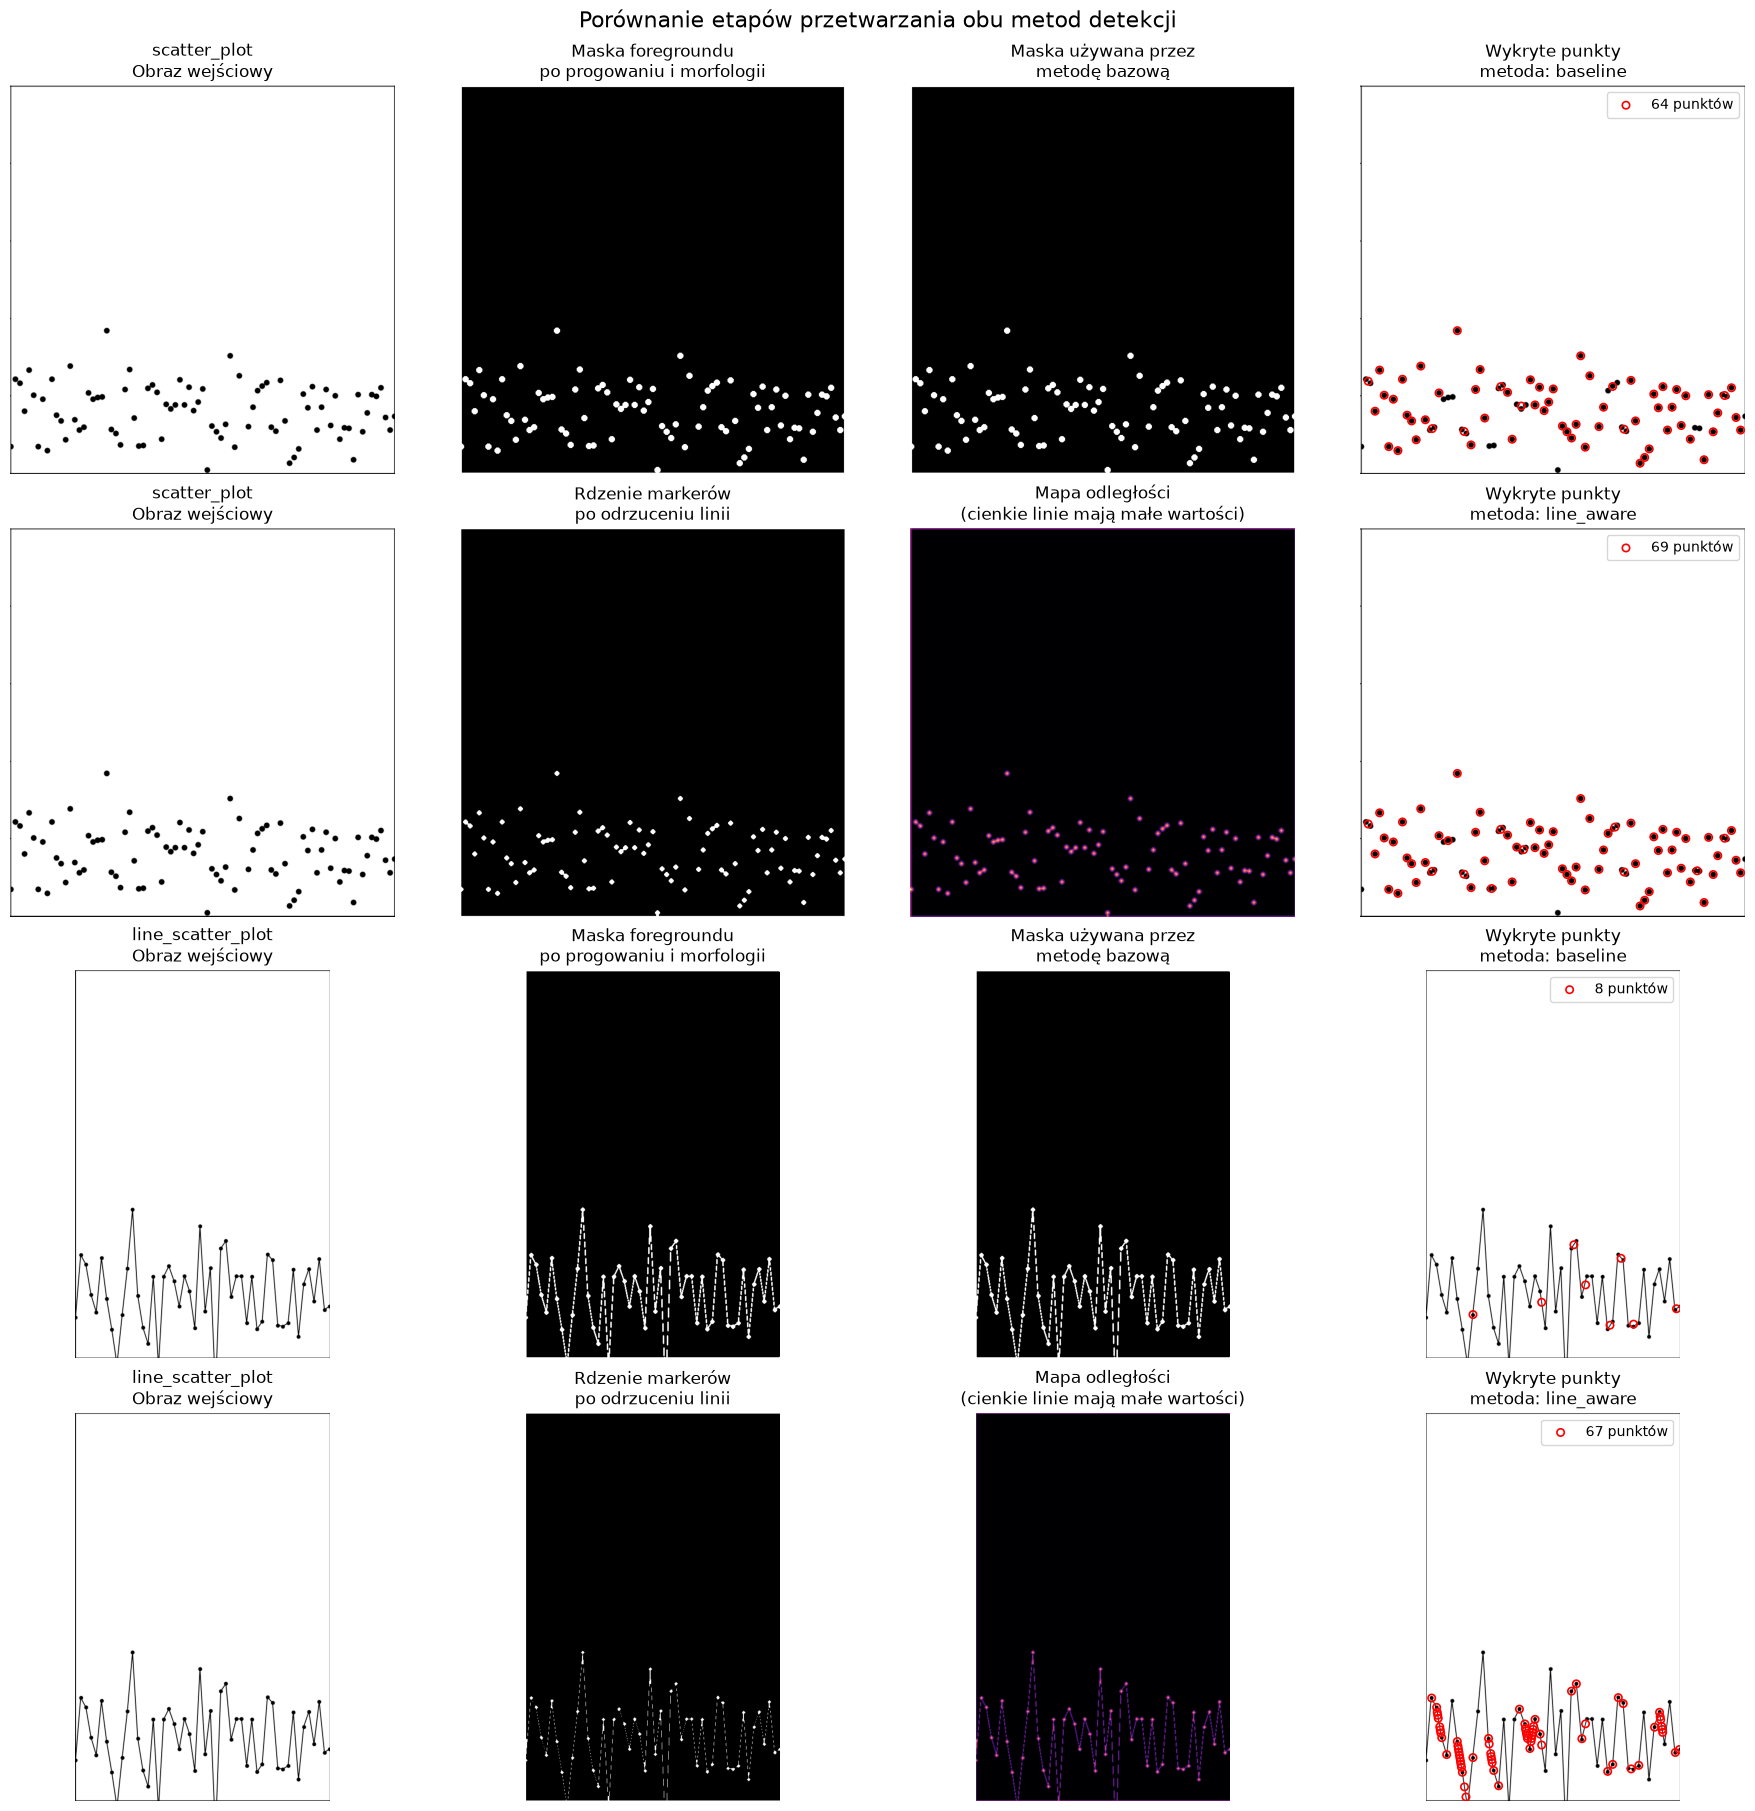

In [3]:
fig, axes = plt.subplots(
    nrows=len(demo_cases), ncols=4, figsize=(18, 18), constrained_layout=True
)

for row, (plot_style, method) in enumerate(demo_cases):
    image_id, metadata = demo_images[plot_style]
    image = cv2.imread(str(DATA_DIR / "images" / f"{image_id}.png"))
    config = load_demo_config(image_id, metadata)
    plot_image = isolate_plot_area(image, config)
    foreground_mask = create_image_mask(plot_image)

    if method == "baseline":
        detected_points = detect_points(plot_image, config)
        axes[row, 2].imshow(foreground_mask, cmap="gray")
        axes[row, 2].set_title("Maska używana przez\nmetodę bazową")
    else:
        distance_map = cv2.distanceTransform(
            foreground_mask, cv2.DIST_L2, cv2.DIST_MASK_PRECISE
        )
        marker_core_mask = remove_thin_structures(
            foreground_mask, distance_threshold=2.0
        )
        detected_points = detect_points_line_aware(plot_image, config)
        axes[row, 2].imshow(distance_map, cmap="magma")
        axes[row, 2].set_title("Mapa odległości\n(cienkie linie mają małe wartości)")

    axes[row, 0].imshow(cv2.cvtColor(plot_image, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f"{plot_style}\nObraz wejściowy")
    axes[row, 1].imshow(
        marker_core_mask if method == "line_aware" else foreground_mask,
        cmap="gray",
    )
    axes[row, 1].set_title(
        "Rdzenie markerów\npo odrzuceniu linii"
        if method == "line_aware"
        else "Maska foregroundu\npo progowaniu i morfologii"
    )

    axes[row, 3].imshow(cv2.cvtColor(plot_image, cv2.COLOR_BGR2RGB))
    if detected_points:
        xmin, ymin, _, _ = config["plot_bbox"]
        x_points = [point["x_px"] - xmin for point in detected_points]
        y_points = [point["y_px"] - ymin for point in detected_points]
        axes[row, 3].scatter(
            x_points,
            y_points,
            s=28,
            facecolors="none",
            edgecolors="red",
            linewidths=1.2,
            label=f"{len(detected_points)} punktów",
        )
        axes[row, 3].legend(loc="upper right")
    axes[row, 3].set_title(f"Wykryte punkty\nmetoda: {method}")

    for axis in axes[row]:
        axis.set_axis_off()

fig.suptitle("Porównanie etapów przetwarzania obu metod detekcji", fontsize=16)
plt.show()